## Trabalho 2 da disciplina de Aprendizado de Máquina Profundo

#### Rede Neural Convolucional (CNN) para uma tarefa de regressão a partir de imagens. O dataset fornecido consiste em imagens de bovinos acompanhadas de anotações referentes a características físicas dos animais. O objetivo do trabalho é desenvolver um modelo capaz de estimar, a partir de uma imagem, simultaneamente a altura (cm) e o peso (kg) do animal.


In [1]:
import csv
from pathlib import Path
import pandas as pd
from skimage import io
import numpy as np
import matplotlib.pyplot as plt

#### 1. Faça o download do dataset em https://raw.githubusercontent.com/tltsilveira/ufsm00993/main/dataset_8.zip. Utilize !wget e !unzip para acessar os dados via Google Colab. O conjunto de dados contém um diretório images, com as imagens dos animais, e um arquivo annotations.csv, contendo as respectivas anotaçoes. A primeira coluna do arquivo annotations.csv identifica a imagem correspondente, enquanto a segunda e a terceira colunas contem, respectivamente, os valores de altura e peso associados a imagem. Utilize o modulo csv para leitura das anotacoes e o modulo skimage.io para leitura das imagens.


In [3]:
# !wget https://raw.githubusercontent.com/tltsilveira/ufsm00993/main/dataset_8.zip

In [8]:
# !unzip dataset_8.zip

### leitura das anotações


In [2]:
pasta_dados = Path(".")
pasta_imagens = pasta_dados / "images"
arquivo_anotacoes = pasta_dados / "annotations.csv"

In [3]:
anotacoes = []

with arquivo_anotacoes.open(newline="", encoding="utf-8") as arquivo:
    leitor = csv.reader(arquivo)

    for identificador, altura, peso in leitor:
        anotacoes.append({
            "id": identificador,
            "altura_cm": float(altura),
            "peso_kg": float(peso),
        })

print("número de anotações:", len(anotacoes))
anotacoes[:3]

número de anotações: 513


[{'id': '001', 'altura_cm': 123.0, 'peso_kg': 279.0},
 {'id': '002', 'altura_cm': 130.0, 'peso_kg': 296.0},
 {'id': '003', 'altura_cm': 112.0, 'peso_kg': 212.0}]

In [4]:
arquivos_imagens = sorted(pasta_imagens.iterdir())

for anotacao in anotacoes:
    anotacao["caminho"] = pasta_imagens / f"{anotacao['id']}.jpg"

caminhos_anotados = {anotacao["caminho"] for anotacao in anotacoes}

arquivos_sem_anotacao = [caminho for caminho in arquivos_imagens if caminho not in caminhos_anotados]

print("imagens sem anotação:", len(arquivos_sem_anotacao))
for caminho in arquivos_sem_anotacao:
    print(caminho.name)

imagens sem anotação: 1
334.jpg


tem 514 imagens e 513 anotações. a imagem `334.jpg` não tem anotação e fica fora do conjunto de dados. vamos usar as anotações como referência para selecionar e ordenar as imagens.


In [5]:
df = pd.DataFrame(anotacoes)
df.shape

(513, 4)

In [13]:
df.head()

,id,altura_cm,peso_kg,caminho
0,001,123.0,279.0,images/001.jpg
1,002,130.0,296.0,images/002.jpg
2,003,112.0,212.0,images/003.jpg
3,004,110.0,202.0,images/004.jpg
4,005,114.0,205.0,images/005.jpg


In [14]:
df.isna().sum()

id           0
altura_cm    0
peso_kg      0
caminho      0
dtype: int64

In [15]:
df["id"].duplicated().sum()

np.int64(0)

### plot de algumas das imagens


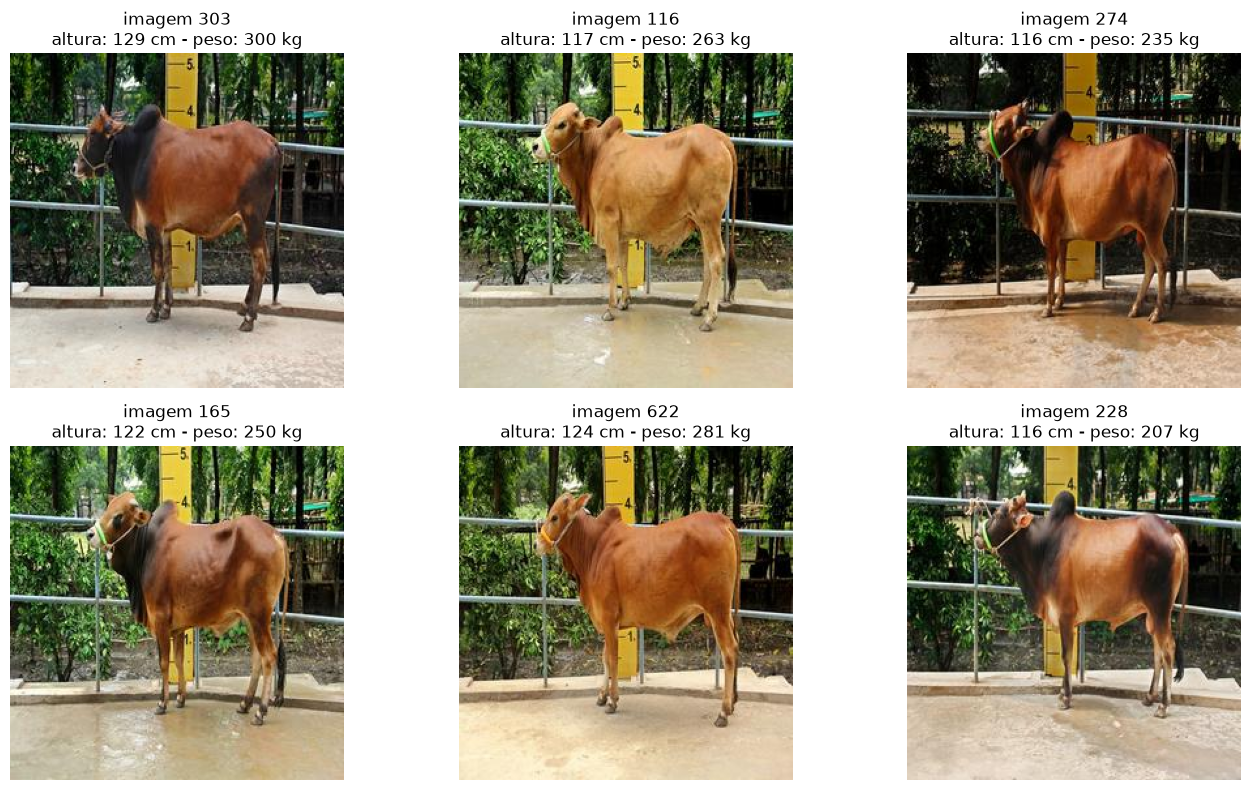

In [16]:
imagens_random = df.sample(n=6, random_state=7)

fig, eixos = plt.subplots(2, 3, figsize=(14, 8))
for eixo, (_, linha) in zip(eixos.flat, imagens_random.iterrows()):
    imagem = io.imread(linha["caminho"])
    eixo.imshow(imagem)
    eixo.set_title(f"imagem {linha['id']}\naltura: {linha['altura_cm']:.0f} cm - peso: {linha['peso_kg']:.0f} kg")
    eixo.axis("off")

plt.tight_layout()
plt.show()

### estatísticas dos rótulos


In [12]:
df[["altura_cm", "peso_kg"]].describe()

,altura_cm,peso_kg
count,513.000000,513.000000
mean,118.530214,256.029240
std,8.220566,74.300259
min,97.000000,150.000000
25%,113.000000,213.000000
50%,118.000000,239.000000
75%,123.000000,273.000000
max,148.000000,816.000000


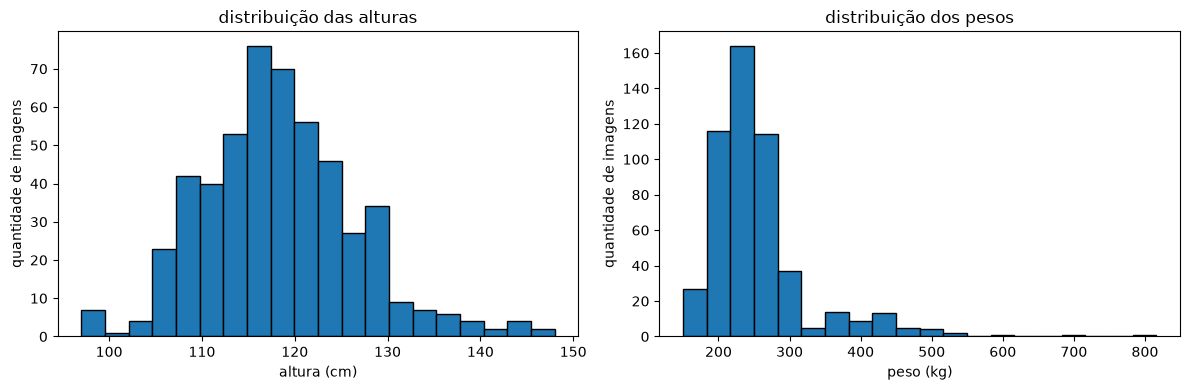

In [13]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

eixos[0].hist(df["altura_cm"], bins=20, edgecolor="black")
eixos[0].set(title="distribuição das alturas", xlabel="altura (cm)", ylabel="quantidade de imagens")

eixos[1].hist(df["peso_kg"], bins=20, edgecolor="black")
eixos[1].set(title="distribuição dos pesos", xlabel="peso (kg)", ylabel="quantidade de imagens")

plt.tight_layout()
plt.show()

pelos histogramas, as alturas têm uma distribuição aproximadamente simétrica. os pesos se concentram entre 200 e 300 kg, com uma cauda à direita em direção aos animais mais pesados.


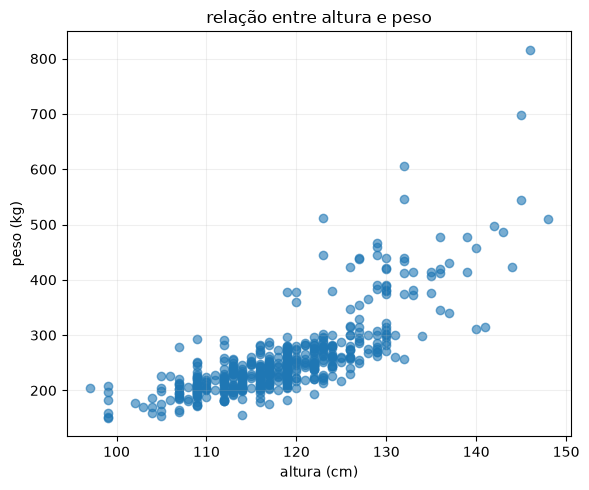

In [14]:
plt.figure(figsize=(6, 5))

plt.scatter(df["altura_cm"], df["peso_kg"], alpha=0.6)
plt.xlabel("altura (cm)")
plt.ylabel("peso (kg)")
plt.title("relação entre altura e peso")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

o gráfico indica uma associação positiva, os bovinos mais altos tendem a ser mais pesados.


#### 2. Trabalhe sobre o conjunto de dados, normalizando os valores dos pixels e realizando uma divisao dos dados para criar conjuntos independentes de treino e validacao. Considere as 50 primeiras imagens de annotations.csv como pertencendo ao conjunto de validacao e as demais pertencentes ao conjunto de treino.


### divisão em treino e validação


In [6]:
df_val = df.iloc[:50].copy()
df_treino = df.iloc[50:].copy()

print("# amostras de treino:", len(df_treino))
print("# amostras de validação:", len(df_val))

# amostras de treino: 463
# amostras de validação: 50


### formato e escala das imagens


In [7]:
formatos = set()
tipos = set()
pixel_min = 255
pixel_max = 0

for caminho in df["caminho"]:
    imagem = io.imread(caminho)

    formatos.add(imagem.shape)
    tipos.add(str(imagem.dtype))
    pixel_min = min(pixel_min, imagem.min())
    pixel_max = max(pixel_max, imagem.max())

print("formatos:", formatos)
print("tipos:", tipos)
print(f"faixa dos pixels: {pixel_min} até {pixel_max}")

formatos: {(256, 256, 3)}
tipos: {'uint8'}
faixa dos pixels: 0 até 255


### carregamento e normalização

vamos converter as imagens para float32 e dividir os pixels por 255, deixando os valores entre 0 e 1. essa escala é fixa e será aplicada igualmente no treino e na validação, sem precisar calcular média e desvio padrão.

os rótulos permanecem nas unidades originais, [altura em cm, peso em kg].


In [8]:
def carrega_e_normaliza_dados(tabela):
    imagens = np.stack([io.imread(caminho) for caminho in tabela["caminho"]]).astype(np.float32) / 255.0
    rotulos = tabela[["altura_cm", "peso_kg"]].to_numpy(dtype=np.float32)

    return imagens, rotulos


X_train, y_train = carrega_e_normaliza_dados(df_treino)
X_val, y_val = carrega_e_normaliza_dados(df_val)

In [9]:
print("treino:", X_train.shape, y_train.shape)
print("validação:", X_val.shape, y_val.shape)
print("tipo das imagens:", X_train.dtype)
print("faixa dos valores do treino:", X_train.min(), X_train.max())
print("faixa dos valores da validação:", X_val.min(), X_val.max())

treino: (463, 256, 256, 3) (463, 2)
validação: (50, 256, 256, 3) (50, 2)
tipo das imagens: float32
faixa dos valores do treino: 0.0 1.0
faixa dos valores da validação: 0.0 1.0


### Enunciados 3 até 8, com os bônus 2, 3 e 4 (o bonus 1, Transfer Learning, fica separado em uma seção abaixo)


### Preparação dos rótulos e avaliação


In [10]:
media_y = y_train.mean(axis=0)
desvio_y = y_train.std(axis=0)
print("médias [altura, peso]:", media_y)
print("desvios [altura, peso]:", desvio_y)

médias [altura, peso]: [118.62635 258.37796]
desvios [altura, peso]: [ 8.395252 76.92018 ]


In [11]:
y_train_norm = (y_train - media_y) / desvio_y
y_val_norm = (y_val - media_y) / desvio_y
print("treino médias:", y_train_norm.mean(axis=0))
print("treino desvios:", y_train_norm.std(axis=0))
print("validação médias:", y_val_norm.mean(axis=0))
print("validação desvios:", y_val_norm.std(axis=0))

treino médias: [-6.1793152e-08  1.1534722e-07]
treino desvios: [1. 1.]
validação médias: [-0.11748907 -0.3132853 ]
validação desvios: [0.73880464 0.45358884]


In [12]:
def desnormaliza_rotulos(valores_norm):
    return np.asarray(valores_norm) * desvio_y + media_y

In [13]:
def avalia_predicao(y_real, y_hat):
    y_real = np.asarray(y_real, dtype=np.float64)
    y_hat = np.asarray(y_hat, dtype=np.float64)
    if y_real.shape != y_hat.shape:
        raise ValueError("os rótulos e predições devem ter o mesmo shape.")

    from sklearn.metrics import r2_score

    erros = y_hat - y_real
    mae = np.mean(np.abs(erros), axis=0)
    rmse = np.sqrt(np.mean(erros ** 2, axis=0))
    r2 = r2_score(y_real, y_hat, multioutput="raw_values")

    return mae, rmse, r2

um baseline para as cnns: chutar a média de altura e peso


In [23]:
previsoes_media = np.tile(media_y, (len(y_val), 1))

avalia_predicao(y_val, previsoes_media)

(array([ 5.06021606, 36.09701294]),
 array([ 6.28038909, 42.40322259]),
 array([-0.02528924, -0.47704048]))

- para altura: MAE de 5,06 cm, RMSE de 6,28 cm
- para peso: MAE de 36,10 kg, RMSE de 42,4 kg


### Implementação dos blocos convolucionais


In [14]:
import tensorflow as tf
from tensorflow.keras import layers, regularizers

tf.keras.utils.set_random_seed(7)
tf.config.experimental.enable_op_determinism()

2026-10-31 08:40:33.292623: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-31 08:40:33.563125: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-31 08:40:34.786485: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [15]:
# ResNet (2015), bloco padrão
def residual_block(x, filtros, stride=1, l2=0.0, usar_residual=True):
    regularizador = regularizers.l2(l2) if l2 > 0 else None
    atalho = x

    # caminho principal: duas convoluções 3x3, com a primeira controlando a redução espacial (stride)
    x = layers.Conv2D(filtros, 3, strides=stride, padding="same", use_bias=False, 
                      kernel_initializer="he_normal", kernel_regularizer=regularizador)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(filtros, 3, padding="same", use_bias=False, 
                      kernel_initializer="he_normal", kernel_regularizer=regularizador)(x)
    x = layers.BatchNormalization()(x)

    # adapta o atalho se a dimensao ou a quantidade de canais mudar
    if usar_residual:
        if stride != 1 or atalho.shape[-1] != filtros:
            atalho = layers.Conv2D(filtros, 1, strides=stride, padding="same", use_bias=False,
                                   kernel_initializer="he_normal", kernel_regularizer=regularizador)(atalho)
            atalho = layers.BatchNormalization()(atalho)

        # combina o caminho principal com o atalho antes da ativação final
        x = layers.Add()([x, atalho])

    return layers.ReLU()(x)

In [16]:
# Xception (2017) / MobileNet (2017)
def separable_residual_block(x, filtros, stride=1, l2=0.0, usar_residual=True):
    regularizador = regularizers.l2(l2) if l2 > 0 else None
    atalho = x

    # caminho principal: duas SeparableConv2D 3x3
    # depthwise convolution, com um kernel 3x3 para cada canal de entrada, depois pointwise convolution (1x1xCinxK) para misturar a informação de todos canais
    x = layers.SeparableConv2D(filtros, 3, strides=stride, padding="same", use_bias=False, 
                               depthwise_initializer="he_normal", pointwise_initializer="he_normal", 
                               depthwise_regularizer=regularizador, pointwise_regularizer=regularizador)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.SeparableConv2D(filtros, 3, padding="same", use_bias=False, 
                               depthwise_initializer="he_normal", pointwise_initializer="he_normal", 
                               depthwise_regularizer=regularizador, pointwise_regularizer=regularizador)(x)
    x = layers.BatchNormalization()(x)

    # adapta o atalho se a dimensão ou a quantidade de canais mudar
    if usar_residual:
        if stride != 1 or atalho.shape[-1] != filtros:
            atalho = layers.Conv2D(filtros, 1, strides=stride, padding="same", use_bias=False, 
                                   kernel_initializer="he_normal", kernel_regularizer=regularizador)(atalho)
            atalho = layers.BatchNormalization()(atalho)

        # combina o caminho principal com o atalho antes da ativação final
        x = layers.Add()([x, atalho])

    return layers.ReLU()(x)

In [17]:
# MobileNetV2 (2018)
def inverted_residual_block(x, filtros, stride=1, expansao=4, l2=0.0, usar_residual=True):
    regularizador = regularizers.l2(l2) if l2 > 0 else None
    atalho = x
    canais_entrada = int(x.shape[-1])
    canais_expandidos = canais_entrada * expansao

    # expande os canais com uma convolução 1x1
    if expansao != 1:
        x = layers.Conv2D(canais_expandidos, 1, padding="same", use_bias=False, 
                          kernel_initializer="he_normal", kernel_regularizer=regularizador)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU(max_value=6)(x)

    # filtra cada canal separadamente com depthwise convolution nesse espaço de maior dimensão
    x = layers.DepthwiseConv2D(3, strides=stride, padding="same", use_bias=False,
                               depthwise_initializer="he_normal", depthwise_regularizer=regularizador)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU(max_value=6)(x)

    # projeta para os canais de saída (K filtros), sem ativação para evitar perda de info / manter o gargalo linear
    x = layers.Conv2D(filtros, 1, padding="same", use_bias=False,
                      kernel_initializer="he_normal", kernel_regularizer=regularizador)(x)
    x = layers.BatchNormalization()(x)

    # soma a entrada somente quando as dimensões são iguais
    if usar_residual and stride == 1 and canais_entrada == filtros:
        x = layers.Add()([x, atalho])

    return x

### Construtor da CNN


In [18]:
def build_cnn(config):
    tipos_blocos = {
        "residual": residual_block,
        "separable": separable_residual_block,
        "inverted": inverted_residual_block,
    }

    tipo_bloco = config["tipo_bloco"]
    canais = config["canais"]
    blocos_por_estagio = config["blocos_por_estagio"]
    cabeca = config["cabeca"]
    l2 = config.get("l2", 0.0)
    dropout = config.get("dropout", 0.0)
    unidades_dense = config.get("unidades_dense", 64)
    regularizador = regularizers.l2(l2) if l2 > 0 else None

    entrada = tf.keras.Input(shape=config.get("input_shape", (256, 256, 3)), name="imagem")

    # convolução inicial, extrai características e reduz a dimensão pela metade
    x = layers.Conv2D(config.get("canais_iniciais", 24), 3, strides=2, padding="same", use_bias=False,
                      kernel_initializer="he_normal", kernel_regularizer=regularizador, name="conv_inicial")(entrada)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # cada estágio reduz a resolução no primeiro bloco
    bloco = tipos_blocos[tipo_bloco]
    
    for filtros, quantidade in zip(canais, blocos_por_estagio):
        for indice in range(quantidade):
            argumentos = {
                "filtros": int(filtros),
                "stride": 2 if indice == 0 else 1,
                "l2": l2,
                "usar_residual": config.get("usar_residual", True),
            }

            if tipo_bloco == "inverted":
                argumentos["expansao"] = config.get("expansao", 4)

            x = bloco(x, **argumentos)

    # transforma os feature maps em um vetor de características usando global average pooling
    x = layers.GlobalAveragePooling2D(name="pooling_global")(x)

    def dense_layer(tensor, nome):
        tensor = layers.Dense(unidades_dense, activation="relu", kernel_initializer="he_normal",
            kernel_regularizer=regularizador, name=f"dense_{nome}")(tensor)

        if dropout > 0:
            tensor = layers.Dropout(dropout, name=f"dropout_{nome}")(tensor)

        return tensor

    if cabeca == "conjunta":
        # as duas tarefas compartilham também a camada densa
        x = dense_layer(x, "conjunta")
        saida = layers.Dense(2, name="predicoes")(x)
    else:
        # cada tarefa recebe sua própria transformação do vetor compartilhado
        altura = dense_layer(x, "altura")
        altura = layers.Dense(1, name="altura")(altura)

        peso = dense_layer(x, "peso")
        peso = layers.Dense(1, name="peso")(peso)

        saida = layers.Concatenate(name="predicoes")([altura, peso])

    modelo = tf.keras.Model(entrada, saida, name=f"cnn_{tipo_bloco}_{cabeca}")

    # inclui os parâmetros treináveis e não treináveis!
    total_parametros = modelo.count_params()
    if total_parametros > 5000000:
        raise ValueError(f"modelo com {total_parametros} parâmetros! o limite é 5.000.000!!!")

    return modelo

In [29]:
config_inicial = {
    "input_shape": tuple(X_train.shape[1:]),
    "tipo_bloco": "residual",
    "canais_iniciais": 24,
    "canais": (32, 64, 128, 192),
    "blocos_por_estagio": (2, 2, 2, 2),
    "cabeca": "conjunta",
    "unidades_dense": 64,
    "expansao": 4,
    "usar_residual": True,
    "dropout": 0.0,
    "l2": 0.0,
}

modelo = build_cnn(config_inicial)
modelo.summary()

I0000 00:00:1793320663.965333   40627 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4177 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "cnn_residual_conjunta"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ imagem (InputLayer) │ (None, 256, 256,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_inicial        │ (None, 128, 128,  │        648 │ imagem[0][0]      │
│ (Conv2D)            │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │         96 │ conv_inicial[0][… │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │      6,912 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │      9,216 │ re_lu_1[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │        768 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 64, 64,    │          0 │ add[0][0]         │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │      9,216 │ re_lu_2[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │      9,216 │ re_lu_3[0][0]   

 Total params: 1,953,322 (7.45 MB)

 Trainable params: 1,949,114 (7.44 MB)

 Non-trainable params: 4,208 (16.44 KB)

In [30]:
resultados_arquiteturas = []

for tipo_bloco in ("residual", "separable", "inverted"):
    for cabeca in ("conjunta", "separada"):
        config = {
            **config_inicial,
            "tipo_bloco": tipo_bloco,
            "cabeca": cabeca,
        }

        modelo_teste = build_cnn(config)
        saida = modelo_teste(X_train[:1], training=False)

        resultados_arquiteturas.append({
            "bloco": tipo_bloco,
            "cabeca": cabeca,
            "parametros": modelo_teste.count_params(),
            "saida": tuple(saida.shape),
        })

        del modelo_teste


pd.DataFrame(resultados_arquiteturas)

2026-10-29 21:37:44.906098: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 90300


,bloco,cabeca,parametros,saida
0,residual,conjunta,1953322,"(1, 2)"
1,residual,separada,1965674,"(1, 2)"
2,separable,conjunta,281282,"(1, 2)"
3,separable,separada,293634,"(1, 2)"
4,inverted,conjunta,759306,"(1, 2)"
5,inverted,separada,771658,"(1, 2)"


### Treinamento inicial de uma CNN para teste


In [31]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(7)

# usa a rede residual sem dropout ou l2 como um baseline simples de CNN
config_treino_inicial = {
    **config_inicial,
    "tipo_bloco": "residual",
    "cabeca": "conjunta",
    "dropout": 0.0,
    "l2": 0.0,
}

modelo = build_cnn(config_treino_inicial)
# minimiza o mse das duas saídas normalizadas usando adam
modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="mse")

print("número de parâmetros:", modelo.count_params())

número de parâmetros: 1953322


In [19]:
from time import perf_counter

In [ ]:
# callbacks de treinamento
# reduceLRonPlateau reduz o LR pela metade depois de 5 épocas sem melhorar a loss de val
# earlyStopping para o treinamento depois de 15 épocas sem melhorar a loss de val, recupera os pesos da época com menor val loss
callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=5, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=15, restore_best_weights=True, verbose=1)
]


inicio_treino = perf_counter()

historico = modelo.fit(X_train, y_train_norm, validation_data=(X_val, y_val_norm), epochs=80, batch_size=16, 
                       shuffle=True, callbacks=callbacks, verbose=2)

tempo_total = perf_counter() - inicio_treino

Epoch 1/80


2026-10-29 21:37:47.465183: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-29 21:37:56.039374: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

29/29 - 9s - 318ms/step - loss: 1.2255 - val_loss: 103.6876 - learning_rate: 0.0010
Epoch 2/80
29/29 - 2s - 78ms/step - loss: 0.4609 - val_loss: 7.4362 - learning_rate: 0.0010
Epoch 3/80
29/29 - 2s - 78ms/step - loss: 0.2945 - val_loss: 0.6674 - learning_rate: 0.0010
Epoch 4/80
29/29 - 2s - 78ms/step - loss: 0.1974 - val_loss: 0.5608 - learning_rate: 0.0010
Epoch 5/80
29/29 - 2s - 78ms/step - loss: 0.1102 - val_loss: 0.2708 - learning_rate: 0.0010
Epoch 6/80
29/29 - 2s - 78ms/step - loss: 0.1361 - val_loss: 1.3148 - learning_rate: 0.0010
Epoch 7/80
29/29 - 2s - 78ms/step - loss: 0.1253 - val_loss: 0.3122 - learning_rate: 0.0010
Epoch 8/80
29/29 - 2s - 78ms/step - loss: 0.0908 - val_loss: 0.3807 - learning_rate: 0.0010
Epoch 9/80
29/29 - 2s - 78ms/step - loss: 0.1214 - val_loss: 0.5835 - learning_rate: 0.0010
Epoch 10/80

Epoch 10: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
29/29 - 2s - 78ms/step - loss: 0.1454 - val_loss: 0.6220 - learning_rate: 0.0010
Epoch 11/

In [33]:
print("melhor val_loss:", min(historico.history["val_loss"]))
print(f"tempo total: {tempo_total / 60:.2f} min")

melhor val_loss: 0.15615567564964294
tempo total: 1.33 min


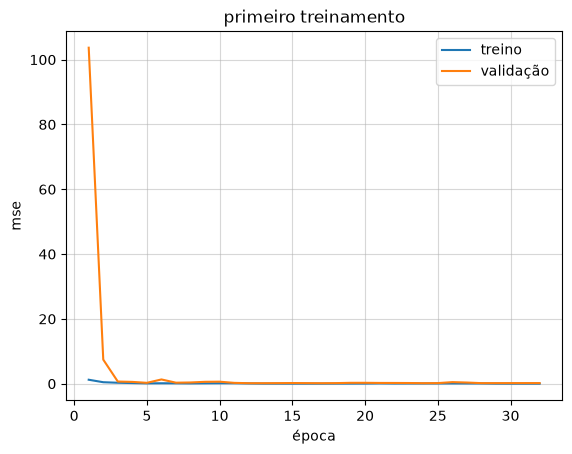

In [34]:
# compara as curvas de mse na escala normalizada, não em cm ou kg
epocas = np.arange(1, len(historico.history["loss"]) + 1)

plt.plot(epocas, historico.history["loss"], label="treino")
plt.plot(epocas, historico.history["val_loss"], label="validação")
plt.xlabel("época")
plt.ylabel("mse")
plt.title("primeiro treinamento")
plt.legend()
plt.grid(alpha=0.5)
plt.show()

In [35]:
previsoes_norm = modelo.predict(X_val)
previsoes = desnormaliza_rotulos(previsoes_norm)

mae_cnn, rmse_cnn, r2_cnn = avalia_predicao(y_val, previsoes)

# compara com a previsão constante das médias do treino
previsoes_media = np.tile(media_y, (len(y_val), 1))
mae_media, rmse_media, r2_media = avalia_predicao(y_val, previsoes_media)

pd.DataFrame({
    "modelo": ["média do treino"] * 2 + ["cnn inicial"] * 2,
    "variável": ["altura", "peso"] * 2,
    "unidade": ["cm", "kg"] * 2,
    "mae": np.concatenate([mae_media, mae_cnn]),
    "rmse": np.concatenate([rmse_media, rmse_cnn]),
    "r2": np.concatenate([r2_media, r2_cnn]),
})

2026-10-29 21:39:06.614354: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 288ms/step


,modelo,variável,unidade,mae,rmse,r2
0,média do treino,altura,cm,5.060216,6.280389,-0.025289
1,média do treino,peso,kg,36.097013,42.403223,-0.477040
2,cnn inicial,altura,cm,3.228642,3.914780,0.601629
3,cnn inicial,peso,kg,18.121904,23.694345,0.538806


o primeiro modelo residual, com ~1,95 milhoes de parâmetros, melhorou os resultados em relação ao baseline de prever a média do treino. o MAE da altura caiu de 5,06 para 3,22 cm, e o do peso de 36,1 para 18,12 kg.

nas primeiras épocas, a loss de validação oscilou bastante. depois, o treino se estabilizou e atingiu a menor loss de validação na época 17, com MSE de aproximadamente 0,156.

a loss de treino se aproximou de zero, enquanto a de validação permaneceu em torno de 0,16, indicando sinal de overfitting. esse resultado serve como baseline para comparar os próximos modelos com data augmentation e regularização.


### Data augmentation e regularização


In [20]:
def build_augmentation(seed=7):
    return tf.keras.Sequential([
        layers.RandomContrast(factor=0.1, seed=seed),
        layers.RandomBrightness(factor=0.05, value_range=(0.0, 1.0), seed=seed + 1),
        layers.RandomFlip(mode="horizontal", seed=seed + 2,)
    ], name="augmentation")

I0000 00:00:1793329883.204677 3896956 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4078 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1660 Ti, pci bus id: 0000:01:00.0, compute capability: 7.5


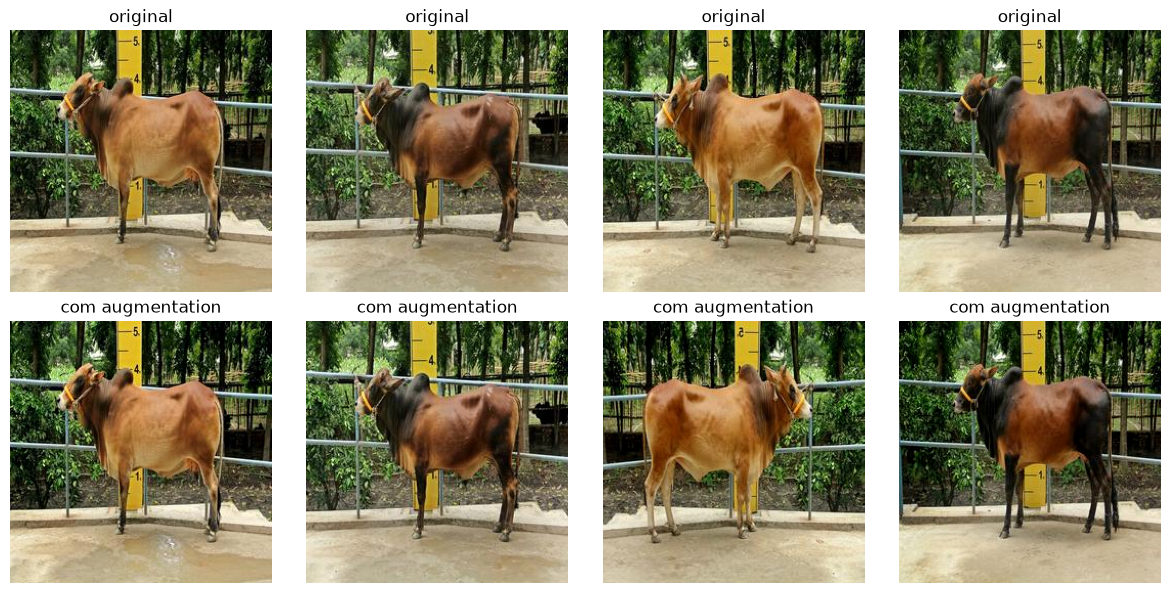

In [30]:
augmentation_preview = build_augmentation()

originais = X_train[:4]
transformadas = augmentation_preview(originais, training=True).numpy()

fig, eixos = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):
    eixos[0, i].imshow(originais[i])
    eixos[0, i].set_title("original")

    eixos[1, i].imshow(transformadas[i])
    eixos[1, i].set_title("com augmentation")

    eixos[0, i].axis("off")
    eixos[1, i].axis("off")

plt.tight_layout()
plt.show()

In [21]:
def build_cnn(config):
    tipos_blocos = {
        "residual": residual_block,
        "separable": separable_residual_block,
        "inverted": inverted_residual_block,
    }

    tipo_bloco = config["tipo_bloco"]
    canais = config["canais"]
    blocos_por_estagio = config["blocos_por_estagio"]
    cabeca = config["cabeca"]
    l2 = config.get("l2", 0.0)
    dropout = config.get("dropout", 0.0)
    unidades_dense = config.get("unidades_dense", 64)
    regularizador = regularizers.l2(l2) if l2 > 0 else None

    entrada = tf.keras.Input(shape=config.get("input_shape", (256, 256, 3)), name="imagem")

    # transforma as imagens somente durante o treinamento
    x = entrada
    if config.get("augmentation", False):
        x = build_augmentation(seed=config.get("seed_augmentation", 7))(x)

    # convolução inicial, extrai características e reduz a dimensão pela metade
    x = layers.Conv2D(config.get("canais_iniciais", 24), 3, strides=2, padding="same", use_bias=False,
                      kernel_initializer="he_normal", kernel_regularizer=regularizador, name="conv_inicial")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # cada estágio reduz a resolução no primeiro bloco
    bloco = tipos_blocos[tipo_bloco]
    
    for filtros, quantidade in zip(canais, blocos_por_estagio):
        for indice in range(quantidade):
            argumentos = {
                "filtros": int(filtros),
                "stride": 2 if indice == 0 else 1,
                "l2": l2,
                "usar_residual": config.get("usar_residual", True),
            }

            if tipo_bloco == "inverted":
                argumentos["expansao"] = config.get("expansao", 4)

            x = bloco(x, **argumentos)

    # transforma os feature maps em um vetor de características usando global average pooling
    x = layers.GlobalAveragePooling2D(name="pooling_global")(x)

    def dense_layer(tensor, nome):
        tensor = layers.Dense(unidades_dense, activation="relu", kernel_initializer="he_normal",
            kernel_regularizer=regularizador, name=f"dense_{nome}")(tensor)

        if dropout > 0:
            tensor = layers.Dropout(dropout, name=f"dropout_{nome}")(tensor)

        return tensor

    if cabeca == "conjunta":
        # as duas tarefas compartilham também a camada densa
        x = dense_layer(x, "conjunta")
        saida = layers.Dense(2, name="predicoes")(x)
    else:
        # cada tarefa recebe sua própria transformação do vetor compartilhado
        altura = dense_layer(x, "altura")
        altura = layers.Dense(1, name="altura")(altura)

        peso = dense_layer(x, "peso")
        peso = layers.Dense(1, name="peso")(peso)

        saida = layers.Concatenate(name="predicoes")([altura, peso])

    modelo = tf.keras.Model(entrada, saida, name=f"cnn_{tipo_bloco}_{cabeca}")

    # inclui os parâmetros treináveis e não treináveis!
    total_parametros = modelo.count_params()
    if total_parametros > 5000000:
        raise ValueError(f"modelo com {total_parametros} parâmetros! o limite é 5.000.000!!!")

    return modelo

In [39]:
comparacao_inicial = pd.DataFrame({
    "modelo": ["média do treino"] * 2 + ["cnn inicial"] * 2,
    "variável": ["altura", "peso"] * 2,
    "unidade": ["cm", "kg"] * 2,
    "mae": np.concatenate([mae_media, mae_cnn]),
    "rmse": np.concatenate([rmse_media, rmse_cnn]),
    "r2": np.concatenate([r2_media, r2_cnn]),
})

historico_inicial = historico.history.copy()

In [40]:
# testando agora no modelo inicial se o augmentation, sem dropout e l2, melhora

config_aug = {
    **config_treino_inicial,
    "augmentation": True,
    "seed_augmentation": 7,
    "dropout": 0.0,
    "l2": 0.0,
}

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(7)

modelo_aug = build_cnn(config_aug)
modelo_aug.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="mse", metrics=[tf.keras.metrics.MeanSquaredError(name="mse_dados")])

In [41]:
callbacks_aug = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_mse_dados", mode="min", factor=0.5, patience=5, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_mse_dados", mode="min", patience=15, restore_best_weights=True, verbose=1,)
]

In [42]:
inicio_aug = perf_counter()

historico_aug = modelo_aug.fit(X_train, y_train_norm, validation_data=(X_val, y_val_norm), epochs=80,
                               batch_size=16, shuffle=True, callbacks=callbacks_aug, verbose=2)

tempo_aug = perf_counter() - inicio_aug

print(f"tempo total: {tempo_aug / 60:.2f} min")
print("melhor época:", np.argmin(historico_aug.history["val_mse_dados"]) + 1)

Epoch 1/80


2026-10-29 21:39:19.150681: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


29/29 - 10s - 345ms/step - loss: 1.2876 - mse_dados: 1.2876 - val_loss: 9.0278 - val_mse_dados: 9.0278 - learning_rate: 0.0010
Epoch 2/80
29/29 - 2s - 82ms/step - loss: 0.6231 - mse_dados: 0.6231 - val_loss: 7.2117 - val_mse_dados: 7.2117 - learning_rate: 0.0010
Epoch 3/80
29/29 - 2s - 82ms/step - loss: 0.3407 - mse_dados: 0.3407 - val_loss: 0.8769 - val_mse_dados: 0.8769 - learning_rate: 0.0010
Epoch 4/80
29/29 - 2s - 81ms/step - loss: 0.2610 - mse_dados: 0.2610 - val_loss: 0.8301 - val_mse_dados: 0.8301 - learning_rate: 0.0010
Epoch 5/80
29/29 - 2s - 81ms/step - loss: 0.2009 - mse_dados: 0.2009 - val_loss: 0.8439 - val_mse_dados: 0.8439 - learning_rate: 0.0010
Epoch 6/80
29/29 - 2s - 80ms/step - loss: 0.1294 - mse_dados: 0.1294 - val_loss: 0.4933 - val_mse_dados: 0.4933 - learning_rate: 0.0010
Epoch 7/80
29/29 - 2s - 81ms/step - loss: 0.1048 - mse_dados: 0.1048 - val_loss: 0.3579 - val_mse_dados: 0.3579 - learning_rate: 0.0010
Epoch 8/80
29/29 - 2s - 81ms/step - loss: 0.0813 - mse_da

In [43]:
previsoes_aug_norm = modelo_aug.predict(X_val, verbose=0)
previsoes_aug = desnormaliza_rotulos(previsoes_aug_norm)

mae_aug, rmse_aug, r2_aug = avalia_predicao(y_val, previsoes_aug)

comparacao_aug = pd.DataFrame({
    "modelo": ["cnn inicial"] * 2 + ["brilho, contraste e flip"] * 2,
    "variável": ["altura", "peso"] * 2,
    "mae": np.concatenate([mae_cnn, mae_aug]),
    "rmse": np.concatenate([rmse_cnn, rmse_aug]),
    "r2": np.concatenate([r2_cnn, r2_aug]),
})

comparacao_aug

2026-10-29 21:41:53.423973: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


,modelo,variável,mae,rmse,r2
0,cnn inicial,altura,3.228642,3.914780,0.601629
1,cnn inicial,peso,18.121904,23.694345,0.538806
2,"brilho, contraste e flip",altura,2.740676,3.348631,0.708521
3,"brilho, contraste e flip",peso,18.323156,22.261551,0.592896


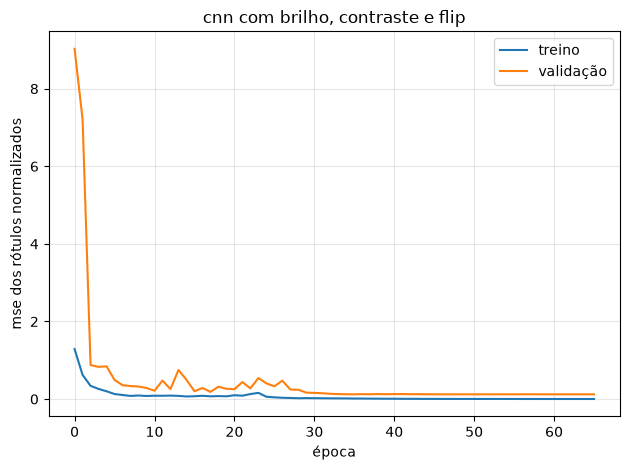

In [44]:
plt.plot(historico_aug.history["mse_dados"], label="treino")
plt.plot(historico_aug.history["val_mse_dados"], label="validação")

plt.xlabel("época")
plt.ylabel("mse dos rótulos normalizados")
plt.title("cnn com brilho, contraste e flip")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [45]:
comparacao_aug_sem_reg = comparacao_aug.copy()
historico_aug_sem_reg = historico_aug.history.copy()

In [46]:
# testando agora no modelo inicial se com augmentation e o dropout e l2 melhora

config_aug_reg = {
    **config_treino_inicial,
    "augmentation": True,
    "seed_augmentation": 7,
    "dropout": 0.2,
    "l2": 1e-5,
}

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(7)

modelo_aug_reg = build_cnn(config_aug_reg)
modelo_aug_reg.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="mse", metrics=[tf.keras.metrics.MeanSquaredError(name="mse_dados")])

In [47]:
callbacks_aug_reg = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_mse_dados", mode="min", factor=0.5, patience=5, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_mse_dados", mode="min", patience=15, restore_best_weights=True, verbose=1,)
]

In [48]:
inicio_aug_reg = perf_counter()

historico_aug_reg = modelo_aug_reg.fit(X_train, y_train_norm, validation_data=(X_val, y_val_norm), epochs=80,
                               batch_size=16, shuffle=True, callbacks=callbacks_aug_reg, verbose=2)

tempo_aug_reg = perf_counter() - inicio_aug_reg

print(f"tempo total: {tempo_aug_reg / 60:.2f} min")
print("melhor época:", np.argmin(historico_aug_reg.history["val_mse_dados"]) + 1)

Epoch 1/80


2026-10-29 21:42:04.780917: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


29/29 - 10s - 362ms/step - loss: 1.2031 - mse_dados: 1.1596 - val_loss: 122.8641 - val_mse_dados: 122.8203 - learning_rate: 0.0010
Epoch 2/80
29/29 - 2s - 83ms/step - loss: 0.7671 - mse_dados: 0.7232 - val_loss: 1.0386 - val_mse_dados: 0.9946 - learning_rate: 0.0010
Epoch 3/80
29/29 - 2s - 82ms/step - loss: 0.4916 - mse_dados: 0.4476 - val_loss: 0.6281 - val_mse_dados: 0.5840 - learning_rate: 0.0010
Epoch 4/80
29/29 - 2s - 83ms/step - loss: 0.3461 - mse_dados: 0.3020 - val_loss: 0.4859 - val_mse_dados: 0.4418 - learning_rate: 0.0010
Epoch 5/80
29/29 - 2s - 82ms/step - loss: 0.2999 - mse_dados: 0.2558 - val_loss: 0.3606 - val_mse_dados: 0.3165 - learning_rate: 0.0010
Epoch 6/80
29/29 - 2s - 82ms/step - loss: 0.2383 - mse_dados: 0.1942 - val_loss: 0.3119 - val_mse_dados: 0.2677 - learning_rate: 0.0010
Epoch 7/80
29/29 - 2s - 81ms/step - loss: 0.2479 - mse_dados: 0.2037 - val_loss: 0.2389 - val_mse_dados: 0.1947 - learning_rate: 0.0010
Epoch 8/80
29/29 - 2s - 82ms/step - loss: 0.2519 - ms

In [49]:
previsoes_aug_reg_norm = modelo_aug_reg.predict(X_val, verbose=0)
previsoes_aug_reg = desnormaliza_rotulos(previsoes_aug_reg_norm)

mae_aug_reg, rmse_aug_reg, r2_aug_reg = avalia_predicao(y_val, previsoes_aug_reg)

comparacao_aug_reg = pd.DataFrame({
    "modelo": ["cnn inicial"] * 2 + ["augmentation + l2 e dropout"] * 2,
    "variável": ["altura", "peso"] * 2,
    "mae": np.concatenate([mae_cnn, mae_aug_reg]),
    "rmse": np.concatenate([rmse_cnn, rmse_aug_reg]),
    "r2": np.concatenate([r2_cnn, r2_aug_reg]),
})

comparacao_aug_reg

2026-10-29 21:44:09.254487: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


,modelo,variável,mae,rmse,r2
0,cnn inicial,altura,3.228642,3.914780,0.601629
1,cnn inicial,peso,18.121904,23.694345,0.538806
2,augmentation + l2 e dropout,altura,2.847261,3.475767,0.685968
3,augmentation + l2 e dropout,peso,19.119942,22.853735,0.570949


In [50]:
comparacao_regularizacao = pd.concat([
    comparacao_aug_sem_reg,
    comparacao_aug_reg[comparacao_aug_reg["modelo"] == "augmentation + l2 e dropout"],
], ignore_index=True)

comparacao_regularizacao

,modelo,variável,mae,rmse,r2
0,cnn inicial,altura,3.228642,3.914780,0.601629
1,cnn inicial,peso,18.121904,23.694345,0.538806
2,"brilho, contraste e flip",altura,2.740676,3.348631,0.708521
3,"brilho, contraste e flip",peso,18.323156,22.261551,0.592896
4,augmentation + l2 e dropout,altura,2.847261,3.475767,0.685968
5,augmentation + l2 e dropout,peso,19.119942,22.853735,0.570949


nessa config inicial, adicionar dropout de 0,2 e l2 de 1e-5 não trouxe uma melhora consistente em relação ao augmentation isolado. os efeitos variaram conforme a tarefa e a métrica, então esses valores serão tratados como opções na busca de hiperparâmetros usando o Optuna.


### Busca de Hiperparâmetros usando o Optuna


In [22]:
import gc
import optuna

In [23]:
# uso do sqlite para guardar as tentativas do optuna para poder carregar e continuar de onde parou se necessário
pasta_estudos = Path("estudos")
pasta_estudos.mkdir(exist_ok=True)
caminho_banco = (pasta_estudos / "busca_cnn.db").resolve()
storage = f"sqlite:///{caminho_banco}"

In [24]:
# função de treinamento e avaliação, ele recria o modelo, otimizador e callbacks a cada trial. retorna só os resultados e depois libera a CNN.

def executar_experimento(config, learning_rate, seed=7):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    modelo_exp = None
    inicio = perf_counter()

    try:
        modelo_exp = build_cnn(config)
        modelo_exp.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss="mse", metrics=[tf.keras.metrics.MeanSquaredError(name="mse_dados")])

        callbacks_exp = [
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_mse_dados", mode="min", factor=0.5, patience=5, min_lr=1e-6, verbose=0),
            tf.keras.callbacks.EarlyStopping(monitor="val_mse_dados", mode="min", patience=15, restore_best_weights=True, verbose=0)
        ]

        historico_exp = modelo_exp.fit(X_train, y_train_norm, validation_data=(X_val, y_val_norm), epochs=80, 
                                       batch_size=16, shuffle=True, callbacks=callbacks_exp, verbose=0)

        valores_val = np.asarray(historico_exp.history["val_mse_dados"])

        previsoes_norm = modelo_exp.predict(X_val, batch_size=16, verbose=0)
        previsoes = desnormaliza_rotulos(previsoes_norm)

        mae, rmse, r2 = avalia_predicao(y_val, previsoes)

        # objetivo sem a penalização l2, calculado nas duas saídas
        mse_val = np.mean((previsoes_norm.astype(np.float64) - y_val_norm) ** 2)

        return {
            "mse_val": float(mse_val),
            "mae_altura": float(mae[0]),
            "mae_peso": float(mae[1]),
            "rmse_altura": float(rmse[0]),
            "rmse_peso": float(rmse[1]),
            "r2_altura": float(r2[0]),
            "r2_peso": float(r2[1]),
            "parametros": int(modelo_exp.count_params()),
            "melhor_epoca": int(np.argmin(valores_val)) + 1,
            "epocas_executadas": len(valores_val),
            "tempo_segundos": float(perf_counter() - inicio),
            "historico": {
                nome: [float(v) for v in valores] for nome, valores in historico_exp.history.items()
            },
        }

    finally:
        del modelo_exp
        tf.keras.backend.clear_session()
        gc.collect()

In [25]:
larguras = {
    "compacta": {
        "canais_iniciais": 16,
        "canais": [24, 48, 96, 144],
    },
    "media": {
        "canais_iniciais": 24,
        "canais": [32, 64, 128, 192],
    },
}


def objetivo_fase1(trial):
    tipo_bloco = trial.suggest_categorical("tipo_bloco", ["residual", "separable", "inverted"] )
    largura = trial.suggest_categorical("largura", ["compacta", "media"])
    quantidade_blocos = trial.suggest_categorical("blocos_por_estagio", [1, 2])
    learning_rate = trial.suggest_categorical("learning_rate", [3e-4, 1e-3])

    config = {
        "input_shape": list(X_train.shape[1:]),
        "tipo_bloco": tipo_bloco,
        **larguras[largura],
        "blocos_por_estagio": [quantidade_blocos] * 4,
        "cabeca": "conjunta",
        "unidades_dense": 64,
        "expansao": 4,
        "usar_residual": True,
        "augmentation": True,
        "seed_augmentation": 7,
        "dropout": 0.0,
        "l2": 0.0,
    }

    # guarda também as escolhas fixas para reconstruir o modelo depois
    trial.set_user_attr("config", config)
    trial.set_user_attr("seed", 7)

    resultado = executar_experimento(config, learning_rate=learning_rate, seed=7)

    for nome, valor in resultado.items():
        trial.set_user_attr(nome, valor)

    return resultado["mse_val"]

In [26]:
espaco_fase1 = {
    "tipo_bloco": ["residual", "separable", "inverted"],
    "largura": ["compacta", "media"],
    "blocos_por_estagio": [1, 2],
    "learning_rate": [3e-4, 1e-3],
}

estudo_fase1 = optuna.create_study(study_name="cnn_fase1_v1", storage=storage, direction="minimize", sampler=optuna.samplers.GridSampler(espaco_fase1, seed=7), 
                                   pruner=optuna.pruners.NopPruner(), load_if_exists=True)

[I 2026-10-31 08:41:26,230] Using an existing study with name 'cnn_fase1_v1' instead of creating a new one.


In [27]:
estudo_fase1.optimize(objetivo_fase1, n_trials=24, n_jobs=1, gc_after_trial=True)

[W 2026-10-31 08:35:52,851] `GridSampler` is re-evaluating a configuration because the grid has been exhausted. This may happen due to a timing issue during distributed optimization or when re-running optimizations on already finished studies.
I0000 00:00:1793446553.684273   10246 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4177 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6
2026-10-31 08:35:55.069239: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=

KeyboardInterrupt: 

In [27]:
def tabela_estudo(estudo):
    linhas = []

    for trial in estudo.trials:
        if trial.state != optuna.trial.TrialState.COMPLETE:
            continue

        atributos = {
            nome: valor
            for nome, valor in trial.user_attrs.items()
            if nome not in ("config", "historico")
        }

        linhas.append({
            "trial": trial.number,
            "mse_val": trial.value,
            **trial.params,
            **atributos,
        })

    return pd.DataFrame(linhas).sort_values("mse_val").reset_index(drop=True)


resultados_fase1 = tabela_estudo(estudo_fase1)
resultados_fase1

,trial,mse_val,tipo_bloco,largura,blocos_por_estagio,learning_rate,epocas_executadas,mae_altura,mae_peso,melhor_epoca,parametros,r2_altura,r2_peso,rmse_altura,rmse_peso,seed,tempo_segundos
0,5,0.121429,residual,media,2,0.0010,66,2.740692,18.322951,51,1953322,0.708518,0.592896,3.348646,22.261541,7,161.950444
1,21,0.153559,residual,compacta,1,0.0010,41,2.686150,22.426541,26,508818,0.671787,0.378021,3.553378,27.516333,7,61.117375
2,8,0.157789,residual,compacta,2,0.0003,29,3.088655,18.595527,14,1102290,0.605044,0.513964,3.897964,24.324106,7,63.774894
3,16,0.157911,residual,media,2,0.0003,41,2.849037,21.299255,26,1953322,0.644569,0.407923,3.697781,26.846755,7,101.775108
4,23,0.158328,residual,compacta,2,0.0010,50,2.684715,23.499482,35,1102290,0.702851,0.249242,3.381041,30.231015,7,101.368073
5,6,0.175939,residual,media,1,0.0010,46,2.974392,23.265008,31,899370,0.618552,0.301698,3.830725,29.155756,7,82.542478
6,11,0.192578,residual,media,1,0.0003,34,3.320719,21.157231,19,899370,0.537236,0.355680,4.219326,28.006160,7,63.210191
7,9,0.230660,residual,compacta,1,0.0003,34,3.333999,26.242838,19,508818,0.524033,0.020515,4.279094,34.530394,7,52.238962
8,22,0.288695,separable,compacta,1,0.0010,35,3.661064,28.452249,20,90882,0.365446,-0.122901,4.940805,36.972046,7,50.204118
9,4,0.328485,inverted,compacta,1,0.0003,38,4.503046,27.523848,23,152946,0.195044,-0.057627,5.564797,35.881370,7,100.808284


In [28]:
class LimiteParametrosError(ValueError):
    pass

In [29]:
def build_cnn(config):
    tipos_blocos = {
        "residual": residual_block,
        "separable": separable_residual_block,
        "inverted": inverted_residual_block,
    }

    tipo_bloco = config["tipo_bloco"]
    canais = config["canais"]
    blocos_por_estagio = config["blocos_por_estagio"]
    cabeca = config["cabeca"]
    l2 = config.get("l2", 0.0)
    dropout = config.get("dropout", 0.0)
    unidades_dense = config.get("unidades_dense", 64)
    regularizador = regularizers.l2(l2) if l2 > 0 else None

    entrada = tf.keras.Input(shape=config.get("input_shape", (256, 256, 3)), name="imagem")

    # transforma as imagens somente durante o treinamento
    x = entrada
    if config.get("augmentation", False):
        x = build_augmentation(seed=config.get("seed_augmentation", 7))(x)

    # convolução inicial, extrai características e reduz a dimensão pela metade
    x = layers.Conv2D(config.get("canais_iniciais", 24), 3, strides=2, padding="same", use_bias=False,
                      kernel_initializer="he_normal", kernel_regularizer=regularizador, name="conv_inicial")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # cada estágio reduz a resolução no primeiro bloco
    bloco = tipos_blocos[tipo_bloco]
    
    for filtros, quantidade in zip(canais, blocos_por_estagio):
        for indice in range(quantidade):
            argumentos = {
                "filtros": int(filtros),
                "stride": 2 if indice == 0 else 1,
                "l2": l2,
                "usar_residual": config.get("usar_residual", True),
            }

            if tipo_bloco == "inverted":
                argumentos["expansao"] = config.get("expansao", 4)

            x = bloco(x, **argumentos)

    # transforma os feature maps em um vetor de características usando global average pooling
    x = layers.GlobalAveragePooling2D(name="pooling_global")(x)

    def dense_layer(tensor, nome):
        tensor = layers.Dense(unidades_dense, activation="relu", kernel_initializer="he_normal",
            kernel_regularizer=regularizador, name=f"dense_{nome}")(tensor)

        if dropout > 0:
            tensor = layers.Dropout(dropout, name=f"dropout_{nome}")(tensor)

        return tensor

    if cabeca == "conjunta":
        # as duas tarefas compartilham também a camada densa
        x = dense_layer(x, "conjunta")
        saida = layers.Dense(2, name="predicoes")(x)
    else:
        # cada tarefa recebe sua própria transformação do vetor compartilhado
        altura = dense_layer(x, "altura")
        altura = layers.Dense(1, name="altura")(altura)

        peso = dense_layer(x, "peso")
        peso = layers.Dense(1, name="peso")(peso)

        saida = layers.Concatenate(name="predicoes")([altura, peso])

    modelo = tf.keras.Model(entrada, saida, name=f"cnn_{tipo_bloco}_{cabeca}")

    # inclui os parâmetros treináveis e não treináveis!
    total_parametros = modelo.count_params()
    if total_parametros > 5000000:
        raise LimiteParametrosError(f"modelo com {total_parametros} parâmetros. limite é de 5.000.000!")

    return modelo

In [30]:
# função de treinamento e avaliação, ele recria o modelo, otimizador e callbacks a cada trial. retorna só os resultados e depois libera a CNN.

def executar_experimento(config, learning_rate, seed=7, epochs=80):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    modelo_exp = None
    inicio = perf_counter()

    try:
        modelo_exp = build_cnn(config)
        modelo_exp.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss="mse", metrics=[tf.keras.metrics.MeanSquaredError(name="mse_dados")])

        callbacks_exp = [
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_mse_dados", mode="min", factor=0.5, patience=5, min_lr=1e-6, verbose=0),
            tf.keras.callbacks.EarlyStopping(monitor="val_mse_dados", mode="min", patience=15, restore_best_weights=True, verbose=0)
        ]

        historico_exp = modelo_exp.fit(X_train, y_train_norm, validation_data=(X_val, y_val_norm), epochs=epochs, 
                                       batch_size=16, shuffle=True, callbacks=callbacks_exp, verbose=0)

        valores_val = np.asarray(historico_exp.history["val_mse_dados"])

        previsoes_norm = modelo_exp.predict(X_val, batch_size=16, verbose=0)
        previsoes = desnormaliza_rotulos(previsoes_norm)

        mae, rmse, r2 = avalia_predicao(y_val, previsoes)

        # objetivo sem a penalização l2, calculado nas duas saídas
        mse_val = np.mean((previsoes_norm.astype(np.float64) - y_val_norm) ** 2)

        return {
            "mse_val": float(mse_val),
            "mae_altura": float(mae[0]),
            "mae_peso": float(mae[1]),
            "rmse_altura": float(rmse[0]),
            "rmse_peso": float(rmse[1]),
            "r2_altura": float(r2[0]),
            "r2_peso": float(r2[1]),
            "parametros": int(modelo_exp.count_params()),
            "melhor_epoca": int(np.argmin(valores_val)) + 1,
            "epocas_executadas": len(valores_val),
            "tempo_segundos": float(perf_counter() - inicio),
            "historico": {
                nome: [float(v) for v in valores] for nome, valores in historico_exp.history.items()
            },
        }

    finally:
        del modelo_exp
        tf.keras.backend.clear_session()
        gc.collect()

In [32]:
larguras_fase2 = {
    "compacta": {
        "canais_iniciais": 16,
        "canais": [24, 48, 96, 144],
    },
    "media": {
        "canais_iniciais": 24,
        "canais": [32, 64, 128, 192],
    },
    "larga": {
        "canais_iniciais": 32,
        "canais": [48, 96, 160, 256],
    },
}

profundidades_fase2 = {
    "curta": [1, 1, 1, 1],
    "media": [2, 2, 2, 2],
    "longa": [2, 2, 3, 2],
}

In [33]:
def objetivo_fase2(trial):
    largura = trial.suggest_categorical("largura", list(larguras_fase2))
    profundidade = trial.suggest_categorical("profundidade", list(profundidades_fase2))

    cabeca = trial.suggest_categorical("cabeca", ["conjunta", "separada"])
    unidades_dense = trial.suggest_categorical("unidades_dense", [32, 64, 128])

    augmentation = trial.suggest_categorical("augmentation", [False, True])
    dropout = trial.suggest_float("dropout", 0.0, 0.4, step=0.1)
    usar_l2 = trial.suggest_categorical("usar_l2", [False, True])
    l2 = (trial.suggest_float("l2", 1e-7, 1e-4, log=True) if usar_l2 else 0.0)

    learning_rate = trial.suggest_float("learning_rate", 1e-4, 2e-3, log=True)

    config = {
        "input_shape": list(X_train.shape[1:]),
        "tipo_bloco": "residual",
        **larguras_fase2[largura],
        "blocos_por_estagio": profundidades_fase2[profundidade],
        "cabeca": cabeca,
        "unidades_dense": unidades_dense,
        "usar_residual": True,
        "augmentation": augmentation,
        "seed_augmentation": 7,
        "dropout": dropout,
        "l2": l2,
    }

    # guarda as escolhas necessárias para reconstruir cada candidato
    trial.set_user_attr("config", config)
    trial.set_user_attr("seed", 7)
    trial.set_user_attr("epochs_max", 120)

    try:
        resultado = executar_experimento(config, learning_rate=learning_rate, seed=7, epochs=120)

    except LimiteParametrosError as erro:
        # configuração que passa dos limites de params: registra e segue para a próxima
        trial.set_user_attr("motivo_interrupcao", str(erro))
        raise optuna.TrialPruned(str(erro))

    except tf.errors.ResourceExhaustedError as erro:
        # falta de memória fica registrada como falha da tentativa
        trial.set_user_attr("motivo_falha", "memória insuficiente")
        raise

    except FloatingPointError as erro:
        trial.set_user_attr("motivo_falha", str(erro))
        raise

    for nome, valor in resultado.items():
        trial.set_user_attr(nome, valor)

    return resultado["mse_val"]

In [34]:
estudo_fase2 = optuna.create_study(study_name="cnn_fase2_v2", storage=storage, direction="minimize", 
                                   sampler=optuna.samplers.TPESampler(seed=7, n_startup_trials=25), pruner=optuna.pruners.NopPruner(), load_if_exists=True)

[I 2026-10-31 08:36:21,333] Using an existing study with name 'cnn_fase2_v2' instead of creating a new one.


In [52]:
# vamos reavaliar também a config que foi melhor na fase 1, colocando na fila de trials
estudo_fase2.enqueue_trial(
    {
        "largura": "media",
        "profundidade": "media",
        "cabeca": "conjunta",
        "unidades_dense": 64,
        "augmentation": True,
        "dropout": 0.0,
        "usar_l2": False,
        "learning_rate": 1e-3,
    },
    skip_if_exists=True,
)

In [35]:
def continuar_fase2(meta_trials=80):
    trials = estudo_fase2.get_trials(deepcopy=False)

    finalizados = sum(t.state.is_finished() for t in trials)
    restantes = max(0, meta_trials - finalizados)

    print("tentativas finalizadas:", finalizados)
    print("tentativas a executar:", restantes)

    if restantes:
        estudo_fase2.optimize(objetivo_fase2, n_trials=restantes, n_jobs=1,
                              gc_after_trial=True, catch=(tf.errors.ResourceExhaustedError, FloatingPointError), show_progress_bar=True)

In [38]:
continuar_fase2(meta_trials=80)

tentativas finalizadas: 68
tentativas a executar: 12


  0%|          | 0/12 [00:00<?, ?it/s]WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1793390638.746857  333887 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4078 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1660 Ti, pci bus id: 0000:01:00.0, compute capability: 7.5
2026-10-30 17:04:07.254693: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown at

[I 2026-10-30 17:10:23,764] Trial 68 finished with value: 0.12803927196829992 and parameters: {'largura': 'larga', 'profundidade': 'longa', 'cabeca': 'separada', 'unidades_dense': 128, 'augmentation': True, 'dropout': 0.30000000000000004, 'usar_l2': True, 'l2': 1.3902695001432428e-06, 'learning_rate': 0.0005830937223620813}. Best is trial 20 with value: 0.10718231541599374.


Best trial: 20. Best value: 0.107182:   8%|▊         | 1/12 [06:32<1:11:59, 392.69s/it]2026-10-30 17:10:28.133059: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
W0000 00:00:1793391040.307492  339669 conv_ops_gpu.cc:328] None of the algorithms provided by cuDNN frontend heuristics worked; trying fallback algorithms.  Conv: batch: 16
in_depths: 48
out_depths: 96
in: 3

[I 2026-10-30 17:13:06,525] Trial 69 finished with value: 0.11870537830703441 and parameters: {'largura': 'compacta', 'profundidade': 'longa', 'cabeca': 'conjunta', 'unidades_dense': 64, 'augmentation': True, 'dropout': 0.30000000000000004, 'usar_l2': False, 'learning_rate': 0.0019589243179854057}. Best is trial 20 with value: 0.10718231541599374.


Best trial: 20. Best value: 0.107182:  17%|█▋        | 2/12 [09:15<42:54, 257.47s/it]  2026-10-30 17:13:10.107492: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-30 17:13:29.952765: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_datase

... (17 outputs left out)

[I 2026-10-30 18:07:21,317] Trial 78 finished with value: 0.11384252096959731 and parameters: {'largura': 'larga', 'profundidade': 'longa', 'cabeca': 'conjunta', 'unidades_dense': 128, 'augmentation': True, 'dropout': 0.4, 'usar_l2': False, 'learning_rate': 0.0012056902641469887}. Best is trial 70 with value: 0.09809408289460794.


Best trial: 70. Best value: 0.0980941:  92%|█████████▏| 11/12 [1:03:30<06:16, 376.65s/it]2026-10-30 18:07:24.905145: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-30 18:07:44.123318: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_data

[I 2026-10-30 18:13:43,037] Trial 79 finished with value: 0.12116194022150077 and parameters: {'largura': 'larga', 'profundidade': 'longa', 'cabeca': 'conjunta', 'unidades_dense': 128, 'augmentation': True, 'dropout': 0.4, 'usar_l2': False, 'learning_rate': 0.0016503330318150928}. Best is trial 70 with value: 0.09809408289460794.


Best trial: 70. Best value: 0.0980941: 100%|██████████| 12/12 [1:09:52<00:00, 349.38s/it]


In [31]:
# agora, vamos carregar o top-3 trials para ver a questão da variabilidade mudando a seed, e assim escolher como arquitetura final o melhor modelo

from copy import deepcopy
import json

# carregar os resultados
estudo_confirmacao = optuna.load_study(study_name="cnn_fase2_v2", storage=storage)
trials_completos = estudo_confirmacao.get_trials(states=(optuna.trial.TrialState.COMPLETE,))
top3 = sorted(trials_completos, key=lambda trial: trial.value)[:3]

sementes = [7, 8, 9]

pd.DataFrame([
    {
        "trial_origem": trial.number,
        "mse_busca": trial.value,
        "cabeca": trial.user_attrs["config"]["cabeca"],
        "augmentation": trial.user_attrs["config"]["augmentation"],
        "parametros": trial.user_attrs["parametros"],
    }
    for trial in top3
])

,trial_origem,mse_busca,cabeca,augmentation,parametros
0,70,0.098094,conjunta,False,3887202
1,77,0.104761,conjunta,True,3903778
2,20,0.107182,separada,True,3474594


In [32]:
pasta_confirmacao = Path("estudos") / "confirmacao"
pasta_confirmacao.mkdir(parents=True, exist_ok=True)
resultados_confirmacao = []

for trial in top3:
    for seed in sementes:
        config = deepcopy(trial.user_attrs["config"])

        # varia também a sequência de augmentation nos modelos que utilizam
        config["seed_augmentation"] = seed

        learning_rate = trial.params["learning_rate"]
        arquivo = pasta_confirmacao / (f"trial_{trial.number}_seed_{seed}.json")

        if arquivo.exists():
            with arquivo.open(encoding="utf-8") as f:
                registro = json.load(f)

            print(f"carregado: trial {trial.number}, seed {seed}")
        else:
            print(f"treinando: trial {trial.number}, seed {seed}")

            resultado = executar_experimento(config=config, learning_rate=learning_rate, seed=seed, epochs=120)

            registro = {
                "estudo_origem": estudo_confirmacao.study_name,
                "trial_origem": trial.number,
                "seed": seed,
                "config": config,
                "learning_rate": learning_rate,
                "epochs_max": 120,
                **resultado,
            }

            temporario = arquivo.with_suffix(".tmp")
            temporario.write_text(json.dumps(registro, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
            temporario.replace(arquivo)

            print(f"mse de validação: {registro['mse_val']:.4f}")

        resultados_confirmacao.append(registro)

carregado: trial 70, seed 7
carregado: trial 70, seed 8
carregado: trial 70, seed 9
carregado: trial 77, seed 7
carregado: trial 77, seed 8
carregado: trial 77, seed 9
carregado: trial 20, seed 7
carregado: trial 20, seed 8
carregado: trial 20, seed 9


In [44]:
metricas_confirmacao = [
    "mse_val",
    "mae_altura",
    "mae_peso",
    "rmse_altura",
    "rmse_peso",
    "r2_altura",
    "r2_peso",
]

df_confirmacao = pd.DataFrame([
    {
        "trial_origem": resultado["trial_origem"],
        "seed": resultado["seed"],
        **{
            metrica: resultado[metrica]
            for metrica in metricas_confirmacao
        },
        "melhor_epoca": resultado["melhor_epoca"],
        "tempo_segundos": resultado["tempo_segundos"],
    }
    for resultado in resultados_confirmacao
])


df_confirmacao.sort_values(["trial_origem", "seed"])

,trial_origem,seed,mse_val,mae_altura,mae_peso,rmse_altura,rmse_peso,r2_altura,r2_peso,melhor_epoca,tempo_segundos
6,20,7,0.115150,2.566515,19.385785,3.077434,23.823843,0.753821,0.533751,49,220.282195
7,20,8,0.129794,2.416296,22.382648,3.072432,27.266221,0.754621,0.389277,35,174.133183
8,20,9,0.140221,3.049008,17.237423,3.719836,22.308967,0.640316,0.591160,13,100.891747
0,70,7,0.111653,2.521109,18.831819,3.108330,22.586558,0.748853,0.580922,38,190.975848
1,70,8,0.125006,2.620118,18.817755,3.371732,22.910069,0.704485,0.568831,40,196.002016
2,70,9,0.123437,2.481830,18.970052,3.272620,23.697903,0.721603,0.538667,38,188.235605
3,77,7,0.126858,2.727116,18.343909,3.441049,22.519964,0.692210,0.583390,29,159.796704
4,77,8,0.118946,2.328684,19.462292,3.090104,24.615775,0.751790,0.502238,26,148.932835
5,77,9,0.127205,2.754625,18.831184,3.366005,23.540131,0.705488,0.544789,37,187.250390


In [39]:
resumo_confirmacao = (
    df_confirmacao
    .groupby("trial_origem")[metricas_confirmacao]
    .agg(["mean", "std"])
    .sort_values(("mse_val", "mean"))
)

resumo_confirmacao

mse_val           mae_altura             mae_peso            \
                  mean       std       mean       std       mean       std   
trial_origem                                                                 
70            0.120032  0.007299   2.541019  0.071262  18.873208  0.084163   
77            0.124336  0.004672   2.603475  0.238373  18.879129  0.560731   
20            0.128388  0.012595   2.677273  0.330577  19.668618  2.584247   

             rmse_altura            rmse_peso           r2_altura            \
                    mean       std       mean       std      mean       std   
trial_origem                                                                  
70              3.250894  0.133038  23.064843  0.571610  0.724980  0.022376   
77              3.299053  0.184804  23.558623  1.048028  0.716496  0.031278   
20              3.289900  0.372343  24.466343  2.540314  0.716253  0.065764   

               r2_peso            
                  mean       std  
trial_origem                      
70            0.562807  0.021762  
77            0.543472  0.040592  
20            0.504729  0.104024

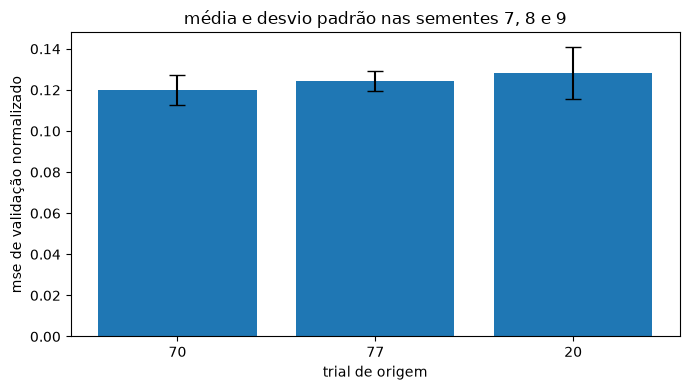

In [40]:
medias = resumo_confirmacao[("mse_val", "mean")]
desvios = resumo_confirmacao[("mse_val", "std")]

plt.figure(figsize=(7, 4))
plt.bar(medias.index.astype(str), medias.values, yerr=desvios.values, capsize=6)
plt.xlabel("trial de origem")
plt.ylabel("mse de validação normalizado")
plt.title("média e desvio padrão nas sementes 7, 8 e 9")
plt.tight_layout()
plt.show()

In [33]:
# trial 70 foi o vencedor, agora vamos testar um mse ponderado para dar mais peso ao peso, que esta com erros maiores

def criar_mse_ponderado(peso_loss):
    def mse_ponderado(y_real, y_hat):
        y_real = tf.cast(y_real, y_hat.dtype)
        erros_quadrados = tf.square(y_hat - y_real)

        # retorna uma loss por amostra, o keras calcula a média do batch
        return (erros_quadrados[:, 0] + peso_loss * erros_quadrados[:, 1]) / (1.0 + peso_loss)

    return mse_ponderado

In [34]:
def executar_experimento(config, learning_rate, seed=7, epochs=80, peso_loss=1.0):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    modelo_exp = None
    inicio = perf_counter()

    try:
        modelo_exp = build_cnn(config)

        # mantém a loss original quando a ponderação é 1:1
        loss = "mse" if peso_loss == 1.0 else criar_mse_ponderado(peso_loss)
        modelo_exp.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss=loss, metrics=[tf.keras.metrics.MeanSquaredError(name="mse_dados")])

        callbacks_exp = [
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_mse_dados", mode="min", factor=0.5, patience=5, min_lr=1e-6, verbose=0),
            tf.keras.callbacks.EarlyStopping(monitor="val_mse_dados", mode="min", patience=15, restore_best_weights=True, verbose=0)
        ]

        historico_exp = modelo_exp.fit(X_train, y_train_norm, validation_data=(X_val, y_val_norm), epochs=epochs, 
                                       batch_size=16, shuffle=True, callbacks=callbacks_exp, verbose=0)

        valores_val = np.asarray(historico_exp.history["val_mse_dados"])

        previsoes_norm = modelo_exp.predict(X_val, batch_size=16, verbose=0)
        previsoes = desnormaliza_rotulos(previsoes_norm)

        mae, rmse, r2 = avalia_predicao(y_val, previsoes)

        # objetivo sem a penalização l2, calculado nas duas saídas
        mse_val = np.mean((previsoes_norm.astype(np.float64) - y_val_norm) ** 2)

        return {
            "mse_val": float(mse_val),
            "mae_altura": float(mae[0]),
            "mae_peso": float(mae[1]),
            "rmse_altura": float(rmse[0]),
            "rmse_peso": float(rmse[1]),
            "r2_altura": float(r2[0]),
            "r2_peso": float(r2[1]),
            "parametros": int(modelo_exp.count_params()),
            "melhor_epoca": int(np.argmin(valores_val)) + 1,
            "epocas_executadas": len(valores_val),
            "tempo_segundos": float(perf_counter() - inicio),
            "historico": {
                nome: [float(v) for v in valores] for nome, valores in historico_exp.history.items()
            },
        }

    finally:
        del modelo_exp
        tf.keras.backend.clear_session()
        gc.collect()

In [42]:
trial_fixo = next(trial for trial in estudo_confirmacao.trials if trial.number == 70)

pasta_loss = Path("estudos") / "loss_ponderada_trial70"
pasta_loss.mkdir(parents=True, exist_ok=True)

resultados_loss = []

for seed in [7, 8, 9]:
    config = deepcopy(trial_fixo.user_attrs["config"])
    config["seed_augmentation"] = seed

    arquivo = pasta_loss / f"peso_2_seed_{seed}.json"

    if arquivo.exists():
        registro = json.loads(arquivo.read_text(encoding="utf-8"))
        print(f"carregado: loss 1:2, seed {seed}")

    else:
        print(f"treinando: loss 1:2, seed {seed}")

        resultado = executar_experimento(config=config, learning_rate=trial_fixo.params["learning_rate"], seed=seed, epochs=120, peso_loss=2.0)

        registro = {
            "trial_origem": 70,
            "seed": seed,
            "peso_loss": 2.0,
            "config": config,
            "learning_rate": trial_fixo.params["learning_rate"],
            "epochs_max": 120,
            **resultado,
        }

        temporario = arquivo.with_suffix(".tmp")
        temporario.write_text(json.dumps(registro, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
        temporario.replace(arquivo)

        print(f"mse sem ponderação: {registro['mse_val']:.4f}")

    resultados_loss.append(registro)

carregado: loss 1:2, seed 7
carregado: loss 1:2, seed 8
carregado: loss 1:2, seed 9


In [45]:
# resultados anteriores do mesmo trial, com a loss original
df_loss_original = df_confirmacao.loc[df_confirmacao["trial_origem"] == 70].copy()

df_loss_original["loss"] = "1:1"
df_loss_ponderada = pd.DataFrame([
    {
        "trial_origem": 70,
        "seed": resultado["seed"],
        "loss": "1:2",
        **{
            metrica: resultado[metrica]
            for metrica in metricas_confirmacao
        },
    }
    for resultado in resultados_loss
])

comparacao_loss = pd.concat([df_loss_original, df_loss_ponderada], ignore_index=True)

In [45]:
comparacao_loss[["loss", "seed", *metricas_confirmacao]].sort_values(["seed", "loss"])

,loss,seed,mse_val,mae_altura,mae_peso,rmse_altura,rmse_peso,r2_altura,r2_peso
0,1:1,7,0.111653,2.521109,18.831819,3.108330,22.586558,0.748853,0.580922
3,1:2,7,0.117119,2.491389,18.182002,3.201088,22.928252,0.733640,0.568146
1,1:1,8,0.125006,2.620118,18.817755,3.371732,22.910069,0.704485,0.568831
4,1:2,8,0.100559,2.240880,18.559894,2.847601,22.566273,0.789219,0.581674
2,1:1,9,0.123437,2.481830,18.970052,3.272620,23.697903,0.721603,0.538667
5,1:2,9,0.114599,2.387710,17.153761,3.275772,21.337079,0.721067,0.626006


In [46]:
comparacao_loss.groupby("loss")[metricas_confirmacao].agg(["mean", "std"])

mse_val           mae_altura             mae_peso            \
          mean       std       mean       std       mean       std   
loss                                                                 
1:1   0.120032  0.007299   2.541019  0.071262  18.873208  0.084163   
1:2   0.110759  0.008923   2.373326  0.125873  17.965219  0.727701   

     rmse_altura            rmse_peso           r2_altura             r2_peso  \
            mean       std       mean       std      mean       std      mean   
loss                                                                            
1:1     3.250894  0.133038  23.064843  0.571610  0.724980  0.022376  0.562807   
1:2     3.108154  0.228714  22.277201  0.834044  0.747975  0.036267  0.591942   

                
           std  
loss            
1:1   0.021762  
1:2   0.030266

In [47]:
config_campeao = deepcopy(trial_fixo.user_attrs["config"])
modelo_contagem = build_cnn(config_campeao)

total_parametros = modelo_contagem.count_params()
limite_parametros = 5000000
margem_parametros = limite_parametros - total_parametros

print(f"parâmetros totais: {total_parametros:,}")
print(f"limite: {limite_parametros:,}")
print(f"margem disponível: {margem_parametros:,}")
print(f"uso do limite: {100 * total_parametros / limite_parametros:.2f}%")

del modelo_contagem

parâmetros totais: 3,887,202
limite: 5,000,000
margem disponível: 1,112,798
uso do limite: 77.74%


a arquitetura escolhida tem 3.887.202 parâmetros totais, aproximadamente 77,74% do limite permitido. resta uma margem de 1.112.798 parâmetros. vamos investigar, em uma busca restrita de 30 trials, se ampliar os canais ou redistribuir os blocos melhora o desempenho com a loss ponderada 1:2. a arquitetura atual será mantida como baseline, já que aumentar a capacidade não garante uma melhor generalização.

In [48]:
perfis_refinamento = {
    "referencia": {
        "canais": [48, 96, 160, 256],
        "blocos_por_estagio": [2, 2, 3, 2],
    },
    "mais_canais_finais": {
        "canais": [48, 96, 176, 272],
        "blocos_por_estagio": [2, 2, 3, 2],
    },
    "mais_canais_intermediarios": {
        "canais": [48, 112, 176, 256],
        "blocos_por_estagio": [2, 2, 3, 2],
    },
    "mais_bloco_estagio2": {
        "canais": [48, 96, 160, 256],
        "blocos_por_estagio": [2, 3, 3, 2],
    },
    "mais_bloco_estagio3": {
        "canais": [48, 96, 160, 256],
        "blocos_por_estagio": [2, 2, 4, 2],
    },
    "canais_e_bloco": {
        "canais": [48, 96, 176, 272],
        "blocos_por_estagio": [2, 2, 4, 2],
    },
}

config_base_refinamento = deepcopy(config_campeao)
config_base_refinamento.update({
    "cabeca": "conjunta",
    "unidades_dense": 64,
    "dropout": 0.4,
    "augmentation": False,
    "l2": 0.0,
    "usar_residual": True,
})

In [49]:
# filtar os perfis que passam do teto de parâmetros máximo (5 MI)

perfis_validos = {}
contagens = []

for nome, perfil in perfis_refinamento.items():
    modelo_contagem = None

    try:
        config = {
            **deepcopy(config_base_refinamento),
            **deepcopy(perfil),
        }

        modelo_contagem = build_cnn(config)
        parametros = modelo_contagem.count_params()

        valido = parametros <= 5000000

        if valido:
            perfis_validos[nome] = deepcopy(perfil)

        contagens.append({
            "perfil": nome,
            "parametros": parametros,
            "incluido": valido,
        })

    except LimiteParametrosError:
        contagens.append({
            "perfil": nome,
            "parametros": "acima de 5 milhões",
            "incluido": False,
        })

    finally:
        del modelo_contagem
        tf.keras.backend.clear_session()
        gc.collect()

pd.DataFrame(contagens)

,perfil,parametros,incluido
0,referencia,3887202,True
1,mais_canais_finais,4443490,True
2,mais_canais_intermediarios,4311906,True
3,mais_bloco_estagio2,4053858,True
4,mais_bloco_estagio3,4349282,True
5,canais_e_bloco,acima de 5 milhões,False


In [35]:
def objetivo_refinamento(trial):
    perfil = trial.suggest_categorical("perfil", list(perfis_validos))
    learning_rate = trial.suggest_float("learning_rate", 6e-4, 2e-3, log=True)

    config = {
        **deepcopy(config_base_refinamento),
        **deepcopy(perfis_validos[perfil]),
    }

    trial.set_user_attr("config", config)
    trial.set_user_attr("seed", 7)
    trial.set_user_attr("peso_loss", 2.0)
    trial.set_user_attr("epochs_max", 120)

    try:
        resultado = executar_experimento(config=config, learning_rate=learning_rate, seed=7, epochs=120, peso_loss=2.0)

    except tf.errors.ResourceExhaustedError:
        trial.set_user_attr("motivo_falha", "memória insuficiente")
        raise

    for nome, valor in resultado.items():
        trial.set_user_attr(nome, valor)

    return resultado["mse_val"]

In [36]:
# agora, criar o estudo e garantir uma comparação inicial de todos os perfis, colocando eles na fila de trials já

estudo_refinamento = optuna.create_study(study_name="cnn_refinamento_capacidade_v1", storage=storage, direction="minimize",
                                         sampler=optuna.samplers.TPESampler(seed=7, n_startup_trials=10,), pruner=optuna.pruners.NopPruner(), load_if_exists=True)

[I 2026-10-31 08:42:10,595] Using an existing study with name 'cnn_refinamento_capacidade_v1' instead of creating a new one.


In [ ]:
for perfil in perfis_validos:
    estudo_refinamento.enqueue_trial(
        {
            "perfil": perfil,
            "learning_rate": trial_fixo.params["learning_rate"],
        },
        skip_if_exists=True,
    )

In [52]:
def continuar_refinamento(meta_trials=30):
    finalizados = sum(trial.state.is_finished() for trial in estudo_refinamento.trials)
    restantes = max(0, meta_trials - finalizados)

    print("tentativas finalizadas:", finalizados)
    print("tentativas a executar:", restantes)

    if restantes:
        estudo_refinamento.optimize(objetivo_refinamento, n_trials=restantes, n_jobs=1, gc_after_trial=True,
                                    catch=(tf.errors.ResourceExhaustedError, FloatingPointError,), show_progress_bar=True)

In [47]:
continuar_refinamento(meta_trials=30)

tentativas finalizadas: 7
tentativas a executar: 23


  0%|          | 0/23 [00:00<?, ?it/s]2026-10-30 23:26:33.264852: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 364118016 exceeds 10% of free system memory.
2026-10-30 23:26:33.879514: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 364118016 exceeds 10% of free system memory.
2026-10-30 23:26:34.162786: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 364118016 exceeds 10% of free system memory.
2026-10-30 23:26:34.410806: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=

[I 2026-10-30 23:32:50,903] Trial 8 finished with value: 0.12389208977809359 and parameters: {'perfil': 'mais_bloco_estagio3', 'learning_rate': 0.0011474117566239589}. Best is trial 1 with value: 0.10875199565212817.


Best trial: 1. Best value: 0.108752:   4%|▍         | 1/23 [06:18<2:18:54, 378.83s/it]2026-10-30 23:32:51.995819: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 364118016 exceeds 10% of free system memory.
2026-10-30 23:32:52.513432: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 364118016 exceeds 10% of free system memory.
2026-10-30 23:33:10.166276: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  t

[I 2026-10-30 23:38:27,382] Trial 9 finished with value: 0.12454018847460294 and parameters: {'perfil': 'mais_bloco_estagio3', 'learning_rate': 0.001579098820394358}. Best is trial 1 with value: 0.10875199565212817.


Best trial: 1. Best value: 0.108752:   9%|▊         | 2/23 [11:55<2:03:52, 353.94s/it]2026-10-30 23:38:46.866811: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-30 23:45:12.985788: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset

... (39 outputs left out)

[I 2026-10-31 01:44:27,258] Trial 29 finished with value: 0.14691431061511262 and parameters: {'perfil': 'mais_canais_intermediarios', 'learning_rate': 0.001970328016951698}. Best is trial 28 with value: 0.10335134258603942.


Best trial: 28. Best value: 0.103351:  96%|█████████▌| 22/23 [2:17:56<06:47, 407.77s/it]2026-10-31 01:44:31.493317: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-31 01:44:47.820651: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_datas

[I 2026-10-31 01:51:32,051] Trial 30 finished with value: 0.11340868877514142 and parameters: {'perfil': 'referencia', 'learning_rate': 0.001271712475050212}. Best is trial 28 with value: 0.10335134258603942.


Best trial: 28. Best value: 0.103351: 100%|██████████| 23/23 [2:25:01<00:00, 378.31s/it]


In [37]:
resultados_refinamento = tabela_estudo(estudo_refinamento)
resultados_refinamento

,trial,mse_val,perfil,learning_rate,epocas_executadas,epochs_max,mae_altura,mae_peso,melhor_epoca,parametros,peso_loss,r2_altura,r2_peso,rmse_altura,rmse_peso,seed,tempo_segundos
0,28,0.103351,referencia,0.001097,49,120,2.330869,18.660176,34,3887202,2.0,0.772940,0.597721,2.955519,22.129221,7,336.648090
1,1,0.108752,mais_canais_finais,0.001236,58,120,2.499428,17.795593,43,4443490,2.0,0.739051,0.635130,3.168410,21.075213,7,210.156344
2,22,0.112160,mais_canais_finais,0.001254,36,120,2.649091,17.669067,21,4443490,2.0,0.739524,0.600747,3.165537,22.045854,7,264.108776
3,30,0.113409,referencia,0.001272,62,120,2.513322,17.404411,47,3887202,2.0,0.736949,0.595439,3.181146,22.191906,7,419.434881
4,18,0.116231,referencia,0.001027,36,120,2.298048,21.895685,21,3887202,2.0,0.801433,0.396931,2.763866,27.094817,7,249.900080
5,23,0.116846,mais_canais_finais,0.001236,53,120,2.584986,18.384211,38,4443490,2.0,0.733353,0.571568,3.202812,22.837242,7,372.395717
6,0,0.117119,referencia,0.001236,85,120,2.491389,18.182002,70,3887202,2.0,0.733640,0.568146,3.201088,22.928252,7,294.178756
7,10,0.118795,mais_bloco_estagio2,0.001034,56,120,2.272930,18.589973,41,4053858,2.0,0.754268,0.497132,3.074639,24.741696,7,406.157153
8,16,0.120981,mais_canais_finais,0.001029,78,120,2.671021,19.002213,63,4443490,2.0,0.718267,0.571389,3.292170,22.842004,7,553.584984
9,2,0.121934,mais_canais_intermediarios,0.001236,62,120,2.514674,18.142970,47,4311906,2.0,0.713403,0.575035,3.320466,22.744636,7,228.736758


In [38]:
melhores_por_perfil = resultados_refinamento.sort_values("mse_val").drop_duplicates("perfil")

melhores_por_perfil[[
    "trial",
    "perfil",
    "parametros",
    "learning_rate",
    "mse_val",
    "mae_altura",
    "mae_peso",
    "rmse_altura",
    "rmse_peso",
]]

,trial,perfil,parametros,learning_rate,mse_val,mae_altura,mae_peso,rmse_altura,rmse_peso
0,28,referencia,3887202,0.001097,0.103351,2.330869,18.660176,2.955519,22.129221
1,1,mais_canais_finais,4443490,0.001236,0.108752,2.499428,17.795593,3.168410,21.075213
7,10,mais_bloco_estagio2,4053858,0.001034,0.118795,2.272930,18.589973,3.074639,24.741696
9,2,mais_canais_intermediarios,4311906,0.001236,0.121934,2.514674,18.142970,3.320466,22.744636
13,5,mais_bloco_estagio3,4349282,0.001147,0.123743,2.469926,19.663101,3.280365,23.684435


In [39]:
estudo_final = optuna.load_study(study_name="cnn_refinamento_capacidade_v1", storage=storage)

top2_final = sorted(estudo_final.get_trials(states=(optuna.trial.TrialState.COMPLETE,)), key=lambda trial: trial.value)[:2]

print("trials selecionados:", [trial.number for trial in top2_final])

trials selecionados: [28, 1]


In [40]:
pasta_final = Path("estudos") / "confirmacao_refinamento"
pasta_final.mkdir(parents=True, exist_ok=True)

resultados_confirmacao_final = []

for trial in top2_final:
    for seed in [7, 8, 9]:
        arquivo = pasta_final / f"trial_{trial.number}_seed_{seed}.json"

        if arquivo.exists():
            registro = json.loads(arquivo.read_text(encoding="utf-8"))
            print(f"carregado: trial {trial.number}, seed {seed}")

        else:
            config = deepcopy(trial.user_attrs["config"])
            config["seed_augmentation"] = seed

            print(f"treinando: trial {trial.number}, seed {seed}")

            resultado = executar_experimento(config=config, learning_rate=trial.params["learning_rate"], seed=seed, epochs=120, peso_loss=2.0)

            registro = {
                "estudo_origem": estudo_final.study_name,
                "trial_origem": trial.number,
                "seed": seed,
                "config": config,
                "learning_rate": trial.params["learning_rate"],
                "peso_loss": 2.0,
                "epochs_max": 120,
                **resultado,
            }

            temporario = arquivo.with_suffix(".tmp")
            temporario.write_text(json.dumps(registro, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
            temporario.replace(arquivo)

        resultados_confirmacao_final.append(registro)

treinando: trial 28, seed 7


I0000 00:00:1793446947.203098    6432 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4177 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6
2026-10-31 08:42:28.519472: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-31 08:42:34.617338: I external/local

treinando: trial 28, seed 8


2026-10-31 08:44:37.390626: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-31 08:47:18.735468: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

treinando: trial 28, seed 9


2026-10-31 08:47:29.220373: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-31 08:49:40.569276: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

... (2 outputs left out)

treinando: trial 1, seed 8


2026-10-31 08:53:21.787284: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-31 08:55:53.821270: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

treinando: trial 1, seed 9


2026-10-31 08:56:04.886291: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-31 08:57:41.470134: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

In [46]:
linhas = []

for resultado in resultados_loss:
    linhas.append({
        "candidato": "trial 70 original, loss 1:2",
        "seed": resultado["seed"],
        **{
            metrica: resultado[metrica]
            for metrica in metricas_confirmacao
        },
    })

for resultado in resultados_confirmacao_final:
    linhas.append({
        "candidato": f"refinamento trial {resultado['trial_origem']}",
        "seed": resultado["seed"],
        **{
            metrica: resultado[metrica]
            for metrica in metricas_confirmacao
        },
    })

In [47]:
df_confirmacao_final = pd.DataFrame(linhas)

df_confirmacao_final.sort_values(["candidato", "seed"])

,candidato,seed,mse_val,mae_altura,mae_peso,rmse_altura,rmse_peso,r2_altura,r2_peso
6,refinamento trial 1,7,0.108752,2.499428,17.795593,3.168410,21.075213,0.739051,0.635130
7,refinamento trial 1,8,0.116528,2.422595,18.735321,3.131566,23.572700,0.745084,0.543529
8,refinamento trial 1,9,0.132212,2.730800,18.800250,3.294414,25.561984,0.717883,0.463235
3,refinamento trial 28,7,0.121818,2.610884,19.041405,3.213023,23.976621,0.731650,0.527751
4,refinamento trial 28,8,0.122365,2.505830,17.408862,3.415716,21.646352,0.696725,0.615086
5,refinamento trial 28,9,0.118657,2.528682,19.623214,3.133456,24.080312,0.744777,0.523658
0,"trial 70 original, loss 1:2",7,0.117119,2.491389,18.182002,3.201088,22.928252,0.733640,0.568146
1,"trial 70 original, loss 1:2",8,0.100559,2.240880,18.559894,2.847601,22.566273,0.789219,0.581674
2,"trial 70 original, loss 1:2",9,0.114599,2.387710,17.153761,3.275772,21.337079,0.721067,0.626006


In [48]:
resumo_final = (
    df_confirmacao_final
    .groupby("candidato")[metricas_confirmacao]
    .agg(["mean", "std"])
    .sort_values(("mse_val", "mean"))
)

resumo_final

mse_val           mae_altura            \
                                 mean       std       mean       std   
candidato                                                              
trial 70 original, loss 1:2  0.110759  0.008923   2.373326  0.125873   
refinamento trial 1          0.119164  0.011950   2.550941  0.160430   
refinamento trial 28         0.120947  0.002002   2.548465  0.055251   

                              mae_peso           rmse_altura            \
                                  mean       std        mean       std   
candidato                                                                
trial 70 original, loss 1:2  17.965219  0.727701    3.108154  0.228714   
refinamento trial 1          18.443721  0.562234    3.198130  0.085395   
refinamento trial 28         18.691160  1.147973    3.254065  0.145537   

                             rmse_peso           r2_altura            \
                                  mean       std      mean       std   
candidato                                                              
trial 70 original, loss 1:2  22.277201  0.834044  0.747975  0.036267   
refinamento trial 1          23.403299  2.248177  0.734006  0.014285   
refinamento trial 28         23.234428  1.376291  0.724384  0.024836   

                              r2_peso            
                                 mean       std  
candidato                                        
trial 70 original, loss 1:2  0.591942  0.030266  
refinamento trial 1          0.547298  0.086009  
refinamento trial 28         0.555498  0.051645

### Escolha final da CNN

depois da busca e da comparação nas sementes 7, 8 e 9, escolhemos a configuração original do trial 70, do estudo da fase 2, com a loss ponderada 1:2 para altura e peso. ela apresentou o menor MSE médio de validação sem ponderação, de aproximadamente 0,1108, e os menores erros médios nas duas tarefas: MAE de 2,37 cm para altura e 17,97 kg para peso. os valores médios de RMSE foram 3,11 cm e 22,28 kg, respectivamente.

a última busca investigou se ampliar os canais ou acrescentar blocos, aproveitando a margem até 5 milhões de parâmetros, melhoraria os resultados. na confirmação, a alternativa maior teve MSE médio de 0,1192, enquanto a arquitetura original com outro learning rate teve 0,1209. assim, nas configurações e sementes avaliadas, o refinamento não trouxe melhora no desempenho médio. mantemos a configuração anterior e encerramos a busca da CNN própria.

o modelo escolhido possui 3.887.202 parâmetros totais, canais [48, 96, 160, 256] e [2, 2, 3, 2] blocos residuais por estágio. utiliza global average pooling, cabeça conjunta com 64 unidades, dropout de 0,4 e learning rate inicial de aproximadamente 0,001236, sem augmentation ou l2 nessa configuração final. o treinamento usa os rótulos padronizados e dá o dobro da contribuição relativa ao erro quadrático do peso.

vamos fixar a semente 7 para a execução final, preservar os melhores pesos e conferir as previsões após salvar e recarregar o modelo. depois apresentaremos as curvas, as métricas e os gráficos de erros dessa execução, além de preparar a inferência no conjunto de teste e a exportação das previsões em csv.